<div style="background-color:#d1ecf1; border-left:6px solid #17a2b8; padding:8px;">
<b> Marathon de Boston 2023
</div>

Questions posées :
1. Le temps au semi suffit-il pour prédire le temps final ?
2. Ajouter l'âge et le sexe améliore-t-il la prédiction ?
3. Comment varie le "positive split" (ralentissement) selon l'âge et le sexe ?

<div style="background-color: #F08975 ; border-left:6px solid #F54927; padding:8px;">
<b> 1. Initialisation et chargement des données
</div>

In [36]:
# Librairies
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


RANDOM_STATE = 42

In [37]:
# Chargement des données
FILE_PATH = "C:/users/laura/Documents/Projets/Marathon-Boston/data/boston_marathon_2023.csv"
df = pd.read_csv(FILE_PATH)
print(f"Dimensions : {df.shape[0]} lignes, {df.shape[1]} colonnes")
df.head()

Dimensions : 26598 lignes, 15 colonnes


,age_group,place_overall,place_gender,place_division,name,team,bib_number,half_time,finish_net,finish_gun,gender,half_time_sec,finish_net_sec,finish_gun_sec,finish_net_minutes
0,18-39,1,1,1,"Chebet, Evans",Team–,1,1H 2M 20S,2H 5M 54S,2H 5M 54S,M,3740.0,7554,7554,125.900000
1,18-39,2,2,2,"Geay, Gabriel",Team–,3,1H 2M 20S,2H 6M 4S,2H 6M 4S,M,3740.0,7564,7564,126.066667
2,18-39,3,3,3,"Kipruto, Benson",Team–,5,1H 2M 19S,2H 6M 6S,2H 6M 6S,M,3739.0,7566,7566,126.100000
3,18-39,4,4,4,"Korir, Albert",Team–,19,1H 2M 20S,2H 8M 1S,2H 8M 1S,M,3740.0,7681,7681,128.016667
4,18-39,5,5,5,"Talbi, Zouhair",Team–,31,1H 2M 20S,2H 8M 35S,2H 8M 35S,M,3740.0,7715,7715,128.583333


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26598 entries, 0 to 26597
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age_group           26598 non-null  str    
 1   place_overall       26598 non-null  int64  
 2   place_gender        26598 non-null  int64  
 3   place_division      26598 non-null  int64  
 4   name                26598 non-null  str    
 5   team                26598 non-null  str    
 6   bib_number          26598 non-null  str    
 7   half_time           26526 non-null  str    
 8   finish_net          26598 non-null  str    
 9   finish_gun          26598 non-null  str    
 10  gender              26598 non-null  str    
 11  half_time_sec       26526 non-null  float64
 12  finish_net_sec      26598 non-null  int64  
 13  finish_gun_sec      26598 non-null  int64  
 14  finish_net_minutes  26598 non-null  float64
dtypes: float64(2), int64(5), str(8)
memory usage: 4.6 MB


In [39]:
df.describe()

,place_overall,place_gender,place_division,half_time_sec,finish_net_sec,finish_gun_sec,finish_net_minutes
count,26598.000000,26598.000000,26598.000000,26526.000000,26598.000000,26598.000000,26598.000000
mean,13314.900331,6782.603391,1484.912587,6412.783646,13351.136928,13526.551921,222.518949
std,7686.501455,4060.054452,1320.170822,1155.276126,2625.292344,2680.975675,43.754872
min,1.000000,1.000000,1.000000,3739.000000,7554.000000,7554.000000,125.900000
25%,6656.250000,3325.250000,469.000000,5548.000000,11464.250000,11584.250000,191.070833
50%,13318.500000,6650.000000,1085.000000,6213.000000,12835.500000,12998.000000,213.925000
75%,19971.750000,9975.000000,2013.000000,7016.000000,14667.000000,14914.000000,244.450000
max,26623.000000,15176.000000,5285.000000,12435.000000,26431.000000,26484.000000,440.516667


<div style="background-color: #F08975 ; border-left:6px solid #F54927; padding:8px;">
<b> 2. Exploration des données et nettoyage
</div>

In [40]:
# Détection des valeurs vides et des doublons
print("Valeurs manquantes par colonne :")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"\nDoublons : {df.duplicated().sum()}")

Valeurs manquantes par colonne :
half_time        72
half_time_sec    72
dtype: int64

Doublons : 0


In [41]:
# Nettoyage : on garde les coureurs avec temps au semi et temps final valides car on veut prédire le temps final à partir du temps au semi
df_clean = df.dropna(subset=["half_time_sec", "finish_net_sec"])
print(f"Lignes conservées : {len(df_clean)} / {len(df)}")

Lignes conservées : 26526 / 26598


<div style="background-color: #F08975 ; border-left:6px solid #F54927; padding:8px;">
<b> 3. Exploration graphique
</div>

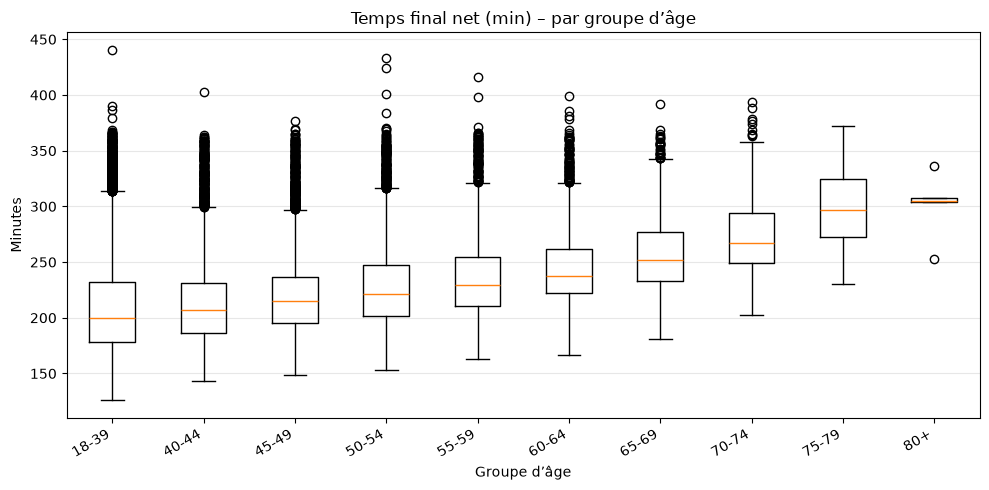

In [42]:
# Boîtes à moustaches par groupe d'âge
# Tri "naturel" des groupes d'âge si format '18-39', '40-44', etc.
def sort_key_age(s):
    m = re.search(r"(\d+)", str(s))
    return int(m.group(1)) if m else 9999

age_groups = sorted(df_clean["age_group"].unique(), key=sort_key_age)
box_data_age = [df_clean.loc[df_clean["age_group"] == ag, "finish_net_minutes"].values for ag in age_groups]

plt.figure(figsize=(10, 5))
plt.boxplot(box_data_age, tick_labels=age_groups, showfliers=True)
plt.title("Temps final net (min) – par groupe d’âge")
plt.ylabel("Minutes")
plt.xlabel("Groupe d’âge")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Une tendance se dessine : lorsque l'âge augmente, le temps au marathon semble augmenter aussi.

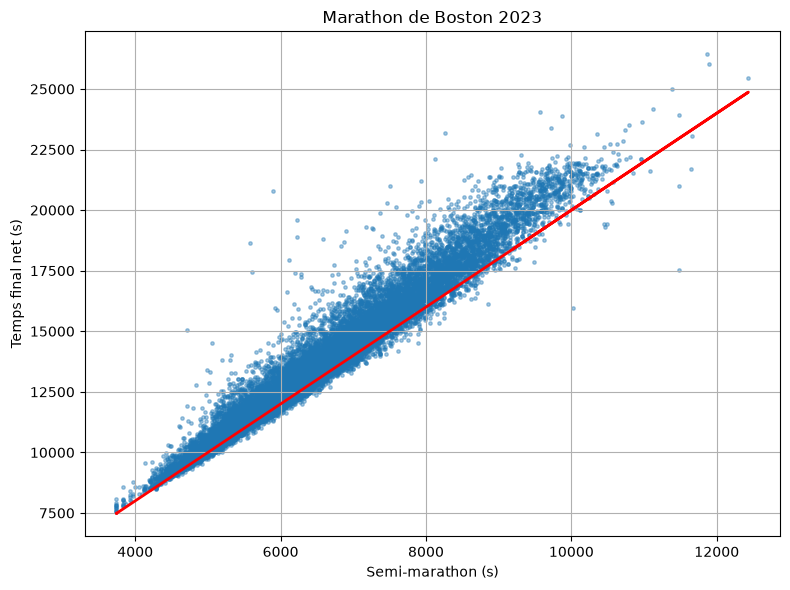

In [43]:
plt.figure(figsize=(8, 6))
plt.scatter(df_clean["half_time_sec"], df_clean["finish_net_sec"], s=6, alpha=0.4)
plt.plot(df_clean["half_time_sec"], 2*df_clean["half_time_sec"], linewidth=2, color="red")
plt.xlabel("Semi-marathon (s)")
plt.ylabel("Temps final net (s)")
plt.title("Marathon de Boston 2023")
plt.grid(True)
plt.tight_layout()
plt.show()

La droite rouge représente un temps identique sur la première et la seconde moitié. Les coureurs les plus proches de cette ligne sont les plus réguliers. Au-dessus de la ligne, les coureurs ont mis plus de temps sur la seconde partie que la première. En dessous de la ligne, ils sont allés plus vite sur la seconde partie que la première. Les meilleurs coureurs sont en bas à gauche du graphique.

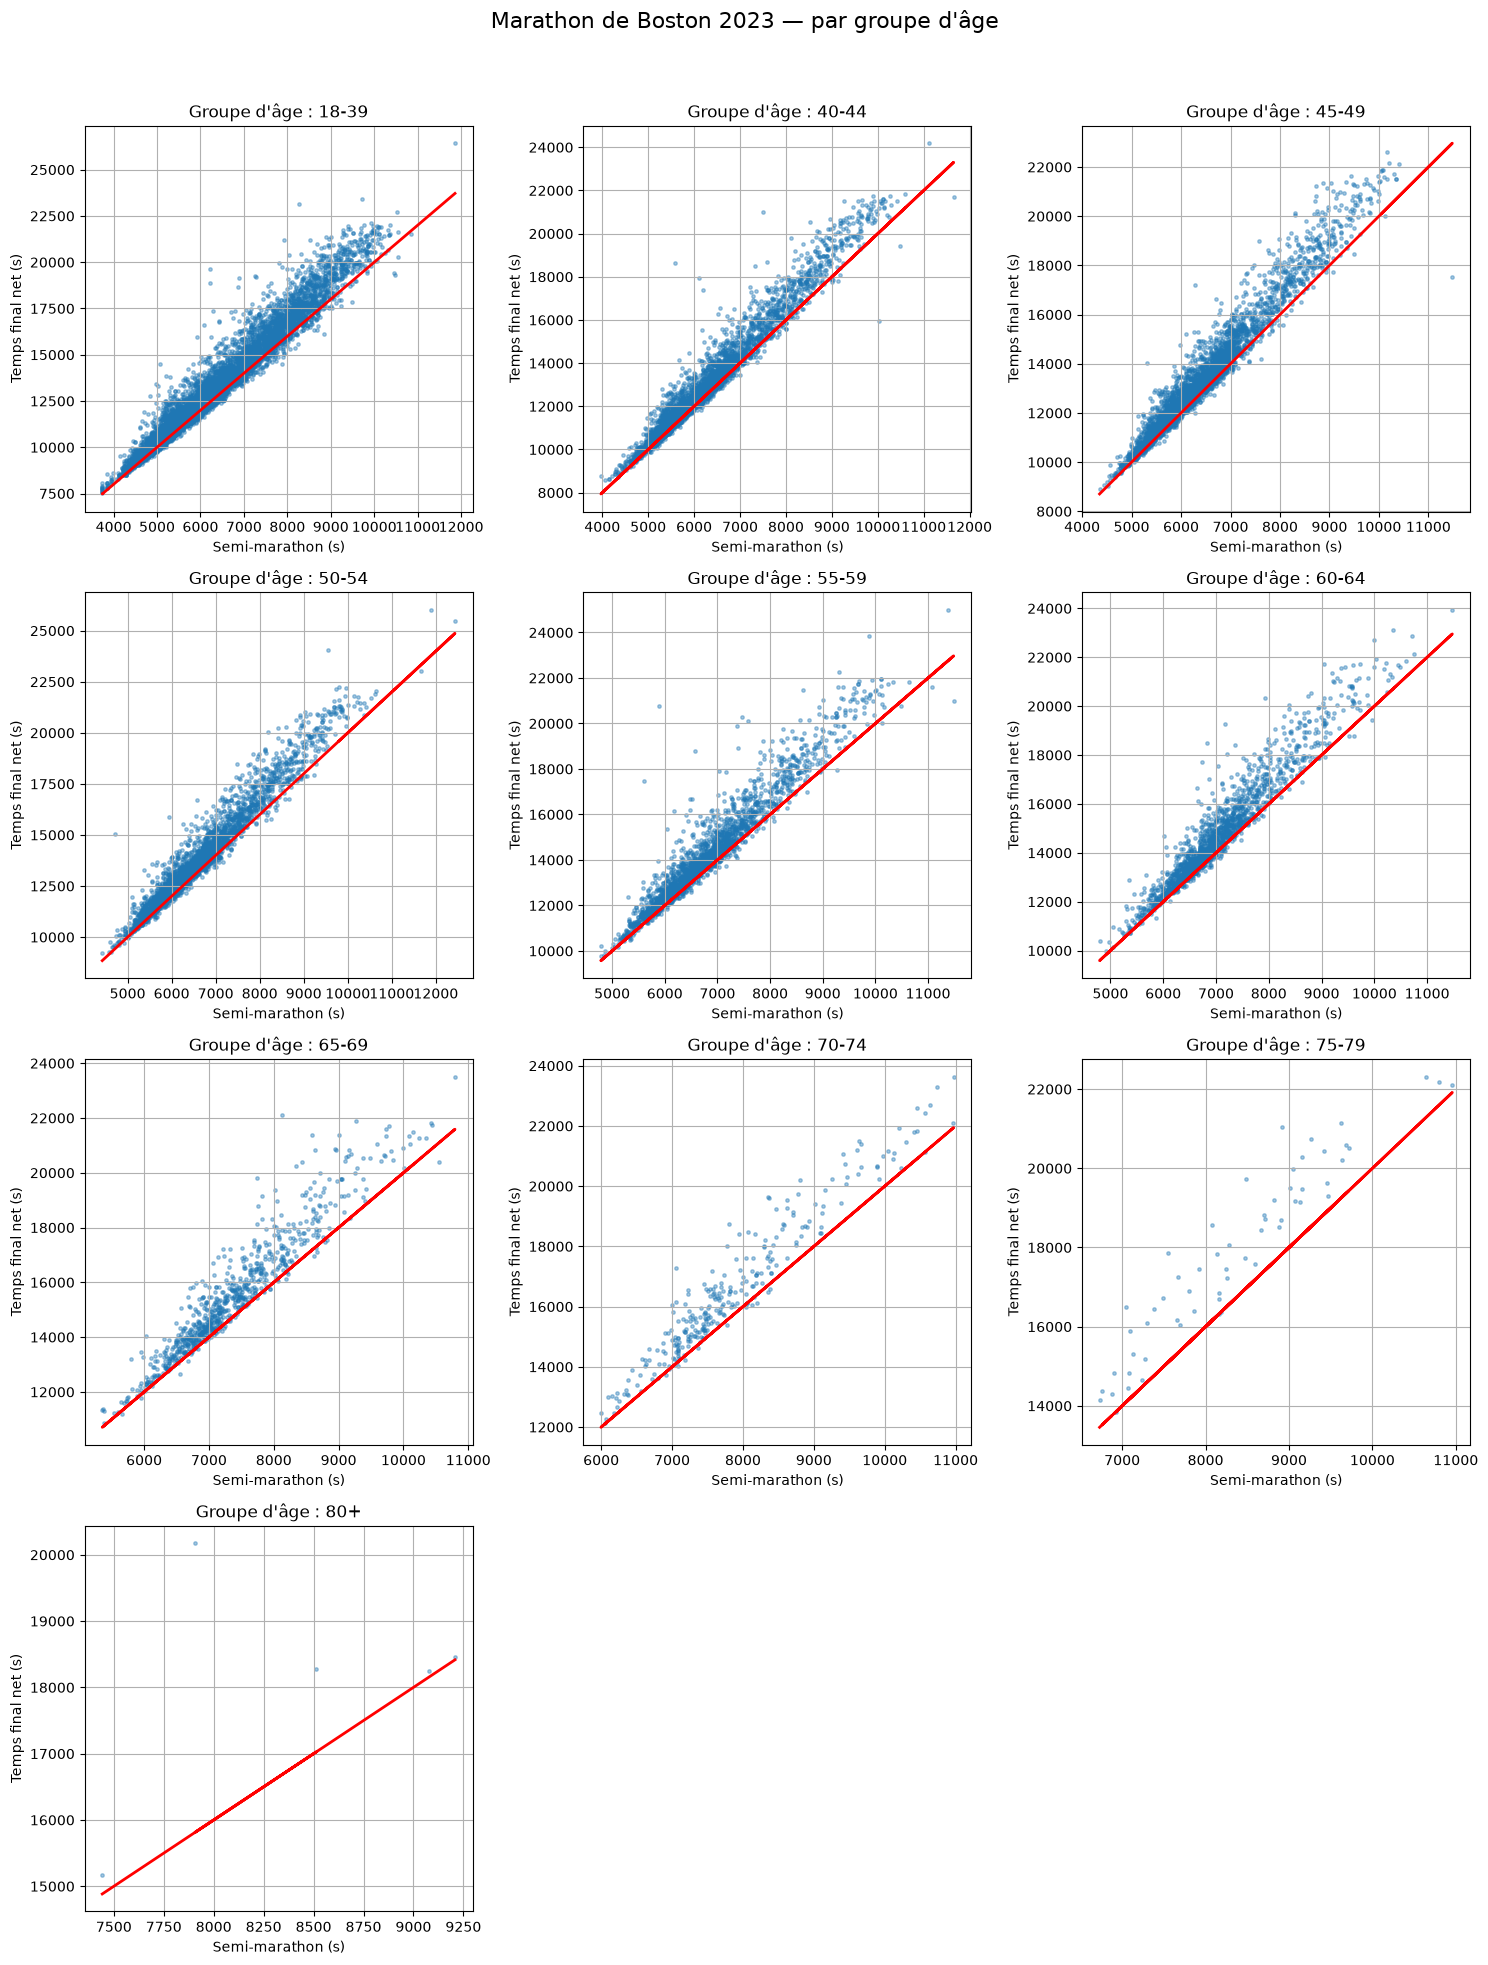

In [44]:
# Variations par classe d'âge
n_groups = len(age_groups)

# Taille de la figure : ajuste dynamiquement selon le nombre de catégories
fig, axes = plt.subplots(
    nrows=(n_groups + 2) // 3,
    ncols=min(3, n_groups),
    figsize=(15, 5 * ((n_groups + 2) // 3))
)

axes = axes.flatten()

for i, age in enumerate(age_groups):
    ax = axes[i]
    subset = df_clean[df_clean["age_group"] == age]

    ax.scatter(subset["half_time_sec"], subset["finish_net_sec"], s=6, alpha=0.4)
    ax.plot(subset["half_time_sec"], 2 * subset["half_time_sec"], linewidth=2, color="red")

    ax.set_xlabel("Semi-marathon (s)")
    ax.set_ylabel("Temps final net (s)")
    ax.set_title(f"Groupe d'âge : {age}")
    ax.grid(True)

# Supprimer les sous-graphiques vides s'il y en a
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Marathon de Boston 2023 — par groupe d'âge", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

<div style="background-color: #F08975 ; border-left:6px solid #F54927; padding:8px;">
<b> 4. Modélisation : prédiction du temps final à partir du temps au semi
</div>

Le temps au semi suffit-il pour prédire le temps final ?

In [45]:
# Sélection caractéristique et variable cible
features = ["half_time_sec"]
target = "finish_net_sec"

In [46]:
# Séparation des données (caractéristiques X et valeurs cibles y)
X = df_clean[features]
y = df_clean[target]

In [47]:
# Séparation des données en 80% de données d'entraînement et 20% de données de test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

In [48]:
# Pas de standardisation : inutile ici, et le coefficient reste directement interprétable
# Choix du modèle
model = LinearRegression()

In [49]:
# Entrainement du modèle
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.22]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['half_time_sec']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-877.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [50]:
# Evaluation du modèle
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r_squared = r2_score(y_test, y_pred)
print(f"R² : {r_squared:.3f} | MAE : {mae/60:.1f} min | RMSE : {rmse/60:.1f} min")
print(f"Coefficient : {model.coef_[0]:.3f}")
print(f"Ordonnée : {model.intercept_:.3f}")

R² : 0.951 | MAE : 6.6 min | RMSE : 9.8 min
Coefficient : 2.219
Ordonnée : -877.723


In [51]:
# Validation croisée à 5 plis
scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error'
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = cross_validate(model, X, y, cv=cv, scoring=scoring)

df_scores = pd.DataFrame({
    'R2': results['test_R2'],
    'MAE': -results['test_MAE']/60,
    'RMSE': -results['test_RMSE']/60
})

df_scores.index = [f'Pli {i+1}' for i in range(len(df_scores))]
df_scores.loc['Moyenne'] = df_scores.mean()

print(df_scores.round(4))

             R2     MAE    RMSE
Pli 1    0.9511  6.5763  9.7532
Pli 2    0.9571  6.3301  9.1948
Pli 3    0.9520  6.4825  9.5358
Pli 4    0.9518  6.4219  9.4302
Pli 5    0.9552  6.4133  9.2384
Moyenne  0.9534  6.4448  9.4305


In [52]:
print(f"R² moyen : {results['test_R2'].mean():.4f}")
print(f"MAE moyen : {-results['test_MAE'].mean() / 60:.2f} min")

R² moyen : 0.9534
MAE moyen : 6.44 min


In [53]:
valeur_a_predire = pd.DataFrame({'half_time_sec': [6000]})
temps_final = model.predict(valeur_a_predire) [0]
print(f"Temps final prédit : {temps_final:.0f} s ({temps_final/ 3600:.2f} h)")

Temps final prédit : 12434 s (3.45 h)


Le temps au semi explique 95 % de la variance du temps final (R² = 0,95), avec une erreur moyenne de 6,6 minutes (RMSE : 9,8 minutes, ce qui indique quelques coureurs nettement moins bien prédits). Le coefficient de 2,22 signifie qu’un coureur plus lent de 1 minute au semi finit en moyenne 2,2 minutes plus lent : l’écart se creuse en seconde moitié, surtout chez les coureurs les plus lents. La validation croisée donne des résultats stables (R² entre 0,951 et 0,957), donc le modèle généralise bien. Il reste toutefois une part d’erreur que le seul temps au semi ne peut pas expliquer.

<div style="background-color: #F08975 ; border-left:6px solid #F54927; padding:8px;">
<b> 5. Modélisation : prédiction du temps final à partir d'autres variables
</div>

Ajouter l'âge et le sexe améliore-t-il la prédiction ?

In [54]:
# Sélection caractéristiques, la variable cible n'a pas changée
features_multi = ["half_time_sec", "age_group", "gender"]

X_multi = pd.get_dummies(
    df_clean[features_multi],
    columns=["age_group", "gender"],
    drop_first=True,
    dtype=int,
)

X_multi.head()

,half_time_sec,age_group_40-44,age_group_45-49,age_group_50-54,age_group_55-59,age_group_60-64,age_group_65-69,age_group_70-74,age_group_75-79,age_group_80+,gender_W
0,3740.0,0,0,0,0,0,0,0,0,0,0
1,3740.0,0,0,0,0,0,0,0,0,0,0
2,3739.0,0,0,0,0,0,0,0,0,0,0
3,3740.0,0,0,0,0,0,0,0,0,0,0
4,3740.0,0,0,0,0,0,0,0,0,0,0


In [55]:
# Séparation des données en 80% de données d'entraînement et 20% de données de test
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.2, random_state=RANDOM_STATE)

In [56]:
# Choix du modèle
model_multi = LinearRegression()

In [57]:
# Entraînement du modèle
model_multi.fit(X_train_m, y_train_m)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 2.25, -23.45, -19.59,..., -35.58, 165.26,-185.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['half_time_sec','age_group_40-44','age_group_45-49',...,'age_group_75-79', 'age_group_80+','gender_W']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-955.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)


In [58]:
# Evaluation du modèle
y_pred_m = model_multi.predict(X_test_m)
mse_m = mean_squared_error(y_test_m, y_pred_m)
rmse_m = np.sqrt(mse_m)
mae_m = mean_absolute_error(y_test_m, y_pred_m)
r2_m = r2_score(y_test_m, y_pred_m)
print(f"R² : {r2_m:.3f} | MAE : {mae_m/60:.1f} min | RMSE : {rmse_m/60:.1f} min")
print(f"Coefficient : {model_multi.coef_[0]:.3f}")
print(f"Coefficient : {model_multi.intercept_:.3f}")

R² : 0.952 | MAE : 6.5 min | RMSE : 9.7 min
Coefficient : 2.246
Coefficient : -955.729


In [59]:
results_m = cross_validate(LinearRegression(), X_multi, y, cv=cv, scoring=scoring)

df_scores_m = pd.DataFrame({
    'R2': results_m['test_R2'],
    'MAE': -results_m['test_MAE']/60,
    'RMSE': -results_m['test_RMSE']/60
})

df_scores_m.index = [f'Pli {i+1}' for i in range(len(df_scores_m))]
df_scores_m.loc['Moyenne'] = df_scores_m.mean()

print(df_scores_m.round(4))

             R2     MAE    RMSE
Pli 1    0.9520  6.5254  9.6644
Pli 2    0.9579  6.2575  9.1076
Pli 3    0.9531  6.4092  9.4307
Pli 4    0.9530  6.3673  9.3126
Pli 5    0.9562  6.3255  9.1350
Moyenne  0.9544  6.3770  9.3301


In [60]:
print(f"R² moyen : {results_m['test_R2'].mean():.4f}")
print(f"MAE moyen : {-results_m['test_MAE'].mean() / 60:.2f} min")

R² moyen : 0.9544
MAE moyen : 6.38 min


In [61]:
comparaison = pd.DataFrame({
    "Simple (temps au semi)": [r_squared, mae / 60, rmse / 60],
    "Multiple (temps au semi + âge + sexe)": [r2_m, mae_m / 60, rmse_m / 60],
}, index=["R²", "MAE (min)", "RMSE (min)"]).round(3)
print(comparaison)

            Simple (temps au semi)  Multiple (temps au semi + âge + sexe)
R²                           0.951                                  0.952
MAE (min)                    6.576                                  6.525
RMSE (min)                   9.753                                  9.664


Ajouter l’âge et le sexe améliore-t-il la prédiction ? Très peu ! Le modèle multiple obtient un R² de 0,952 contre 0,951 pour le modèle simple, et une erreur moyenne de 6,5 minutes contre 6,6 minutes, soit un gain d’environ 3 secondes. Le temps au semi contient donc déjà presque toute l’information nécessaire pour prédire le temps final. L’âge et le sexe n’apportent qu’un gain marginal, qui ne justifie pas à lui seul d’ajouter ces variables pour la prédiction.

In [62]:
coefs = pd.Series(model_multi.coef_, index=X_multi.columns)
print(f"half_time_sec : {coefs['half_time_sec']:.3f}  (sans unité : secondes finales par seconde au semi)")
print("\nEffets de l'âge et du sexe, en minutes :")
print((coefs.drop("half_time_sec") / 60).round(1))

half_time_sec : 2.246  (sans unité : secondes finales par seconde au semi)

Effets de l'âge et du sexe, en minutes :
age_group_40-44   -0.4
age_group_45-49   -0.3
age_group_50-54   -0.6
age_group_55-59   -0.3
age_group_60-64   -0.7
age_group_65-69   -0.1
age_group_70-74   -1.7
age_group_75-79   -0.6
age_group_80+      2.8
gender_W          -3.1
dtype: float64


À temps au semi égal, les femmes finissent en moyenne 3,1 minutes plus vite que les hommes, et les écarts entre groupes d’âge restent inférieurs à 2 minutes (hors 80 ans et plus, groupe de 5 coureurs).